In [73]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn import datasets
from sklearn.base import clone
from scipy.ndimage import convolve
import matplotlib.pyplot as plt
from sklearn.neural_network import BernoulliRBM
from sklearn.pipeline import Pipeline

In [74]:
from scipy.ndimage import convolve

image = np.array([
    [0, 0, 0],
    [0, 9, 0],
    [0, 0, 0]
])

kernel_up = np.array([
    [0, 1, 0],
    [0, 0, 0],
    [0, 0, 0]
])

kernel_down = np.array([
    [0, 0, 0],
    [0, 0, 0],
    [0, 1, 0]
])

kernel_left = np.array([
    [0, 0, 0],
    [1, 0, 0],
    [0, 0, 0]
])

kernel_right = np.array([
    [0, 0, 0],
    [0, 0, 1],
    [0, 0, 0]
])


image, kernel_up, kernel_down, kernel_left, kernel_right

(array([[0, 0, 0],
        [0, 9, 0],
        [0, 0, 0]]),
 array([[0, 1, 0],
        [0, 0, 0],
        [0, 0, 0]]),
 array([[0, 0, 0],
        [0, 0, 0],
        [0, 1, 0]]),
 array([[0, 0, 0],
        [1, 0, 0],
        [0, 0, 0]]),
 array([[0, 0, 0],
        [0, 0, 1],
        [0, 0, 0]]))

In [75]:
shifted_up = convolve(image, kernel_up, mode="constant")
shifted_down = convolve(image, kernel_down, mode="constant")
shifted_right = convolve(image, kernel_right, mode="constant")
shifted_left = convolve(image, kernel_left, mode="constant")
shifted_up, shifted_down, shifted_right, shifted_left

(array([[0, 9, 0],
        [0, 0, 0],
        [0, 0, 0]]),
 array([[0, 0, 0],
        [0, 0, 0],
        [0, 9, 0]]),
 array([[0, 0, 0],
        [0, 0, 9],
        [0, 0, 0]]),
 array([[0, 0, 0],
        [9, 0, 0],
        [0, 0, 0]]))

In [76]:
def nudge_dataset(X, Y):
    """
    This produces a dataset 5 times bigger than the original one,
    by moving the 8x8 images in X around by 1px to left, right, down, up
    """
    direction_vectors = [
        [[0, 1, 0], [0, 0, 0], [0, 0, 0]],
        [[0, 0, 0], [1, 0, 0], [0, 0, 0]],
        [[0, 0, 0], [0, 0, 1], [0, 0, 0]],
        [[0, 0, 0], [0, 0, 0], [0, 1, 0]],
    ]

    def shift(x, w):
        return convolve(x.reshape((8, 8)), mode="constant", weights=w).ravel()

    X = np.concatenate(
        [X] + [np.apply_along_axis(shift, 1, X, vector) for vector in direction_vectors]
    )
    Y = np.concatenate([Y for _ in range(5)], axis=0)
    return X, Y


In [77]:
# Load data
X, y = datasets.load_digits(return_X_y=True)
X.shape, y.shape

((1797, 64), (1797,))

In [78]:
X[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [79]:
X[1]

array([ 0.,  0.,  0., 12., 13.,  5.,  0.,  0.,  0.,  0.,  0., 11., 16.,
        9.,  0.,  0.,  0.,  0.,  3., 15., 16.,  6.,  0.,  0.,  0.,  7.,
       15., 16., 16.,  2.,  0.,  0.,  0.,  0.,  1., 16., 16.,  3.,  0.,
        0.,  0.,  0.,  1., 16., 16.,  6.,  0.,  0.,  0.,  0.,  1., 16.,
       16.,  6.,  0.,  0.,  0.,  0.,  0., 11., 16., 10.,  0.,  0.])

In [80]:
X.max(), X.min()

(np.float64(16.0), np.float64(0.0))

Text(0.5, 1.0, 'Digit Original: 0')

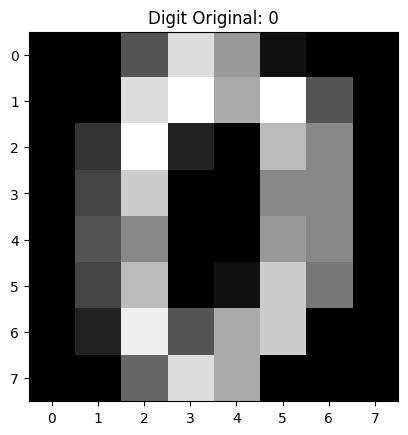

In [81]:
image = X[0].reshape((8, 8))
plt.imshow(image, cmap="gray")
plt.title(f"Digit Original: {y[0]}")

In [82]:
X, y = nudge_dataset(X, y)
X.shape, y.shape

((8985, 64), (8985,))

Text(0.5, 1.0, 'Digit Up: 0')

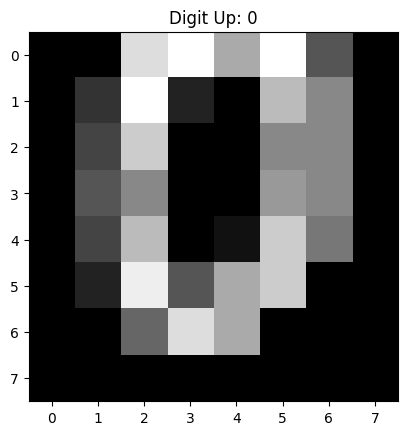

In [83]:
image = X[1797].reshape((8, 8))
plt.imshow(image, cmap="gray")
plt.title(f"Digit Up: {y[1797]}")

Text(0.5, 1.0, 'Digit Left: 0')

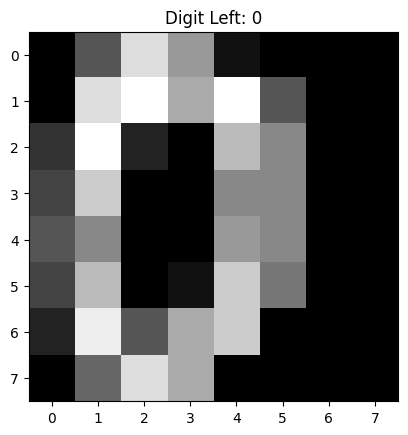

In [84]:
image = X[3594].reshape((8, 8))
plt.imshow(image, cmap="gray")
plt.title(f"Digit Left: {y[3594]}")

Text(0.5, 1.0, 'Digit right: 0')

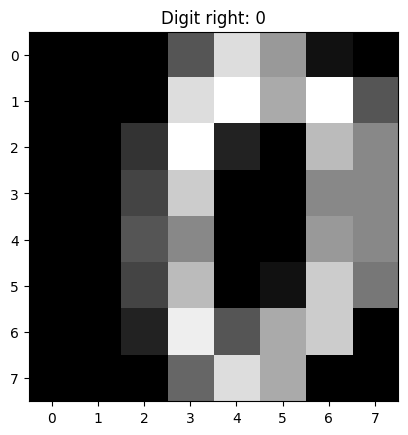

In [85]:
image = X[5391].reshape((8, 8))
plt.imshow(image, cmap="gray")
plt.title(f"Digit right: {y[5391]}")

Text(0.5, 1.0, 'Digit down: 0')

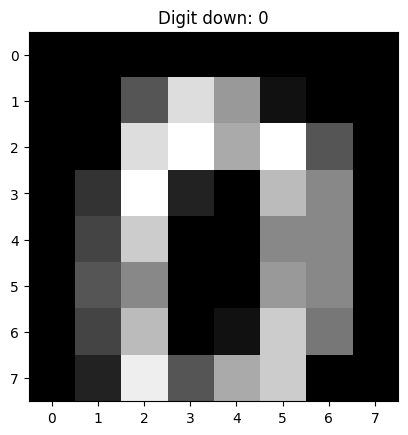

In [86]:
image = X[7188].reshape((8, 8))
plt.imshow(image, cmap="gray")
plt.title(f"Digit down: {y[7188]}")

In [87]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((7188, 64), (1797, 64), (7188,), (1797,))

In [88]:
X_train = X_train / 16.0
X_test = X_test / 16.0

In [89]:
X_train[0]

array([0.    , 0.    , 0.375 , 0.5625, 0.    , 0.    , 0.    , 0.    ,
       0.    , 0.125 , 0.9375, 0.5   , 0.    , 0.    , 0.    , 0.    ,
       0.    , 0.25  , 1.    , 0.3125, 0.    , 0.    , 0.    , 0.    ,
       0.    , 0.5625, 0.75  , 0.4375, 0.75  , 0.125 , 0.    , 0.    ,
       0.    , 0.5625, 1.    , 0.9375, 0.8125, 0.375 , 0.    , 0.    ,
       0.    , 0.8125, 0.875 , 0.125 , 0.8125, 0.375 , 0.    , 0.    ,
       0.    , 0.875 , 0.9375, 0.8125, 1.    , 0.25  , 0.    , 0.    ,
       0.    , 0.0625, 0.625 , 1.    , 0.625 , 0.    , 0.    , 0.    ])

In [90]:
# Models
logistic = LogisticRegression(max_iter=3000, random_state=42)
rbm = BernoulliRBM(random_state=42, verbose=True)

rbm_classifier = Pipeline(
    steps=[("rbm", rbm), ("logistic", logistic)]
    )

In [91]:
rbm.learning_rate = 0.03
rbm.n_iter = 30
rbm.n_components = 48 #64
logistic.C = 6000

In [92]:
raw_pixel = clone(logistic)
raw_pixel.fit(X_train, y_train)
y_pred_raw = raw_pixel.predict(X_test)
print("Logistic on Raw", classification_report(y_test, y_pred_raw))

Logistic on Raw               precision    recall  f1-score   support

           0       0.94      0.91      0.92       182
           1       0.63      0.63      0.63       180
           2       0.78      0.86      0.82       168
           3       0.81      0.73      0.77       183
           4       0.86      0.90      0.88       201
           5       0.78      0.80      0.79       178
           6       0.85      0.93      0.88       165
           7       0.87      0.86      0.87       186
           8       0.69      0.61      0.65       174
           9       0.72      0.71      0.72       180

    accuracy                           0.80      1797
   macro avg       0.79      0.79      0.79      1797
weighted avg       0.79      0.80      0.79      1797



In [93]:
# Train the RBM without labels
rbm.fit(X_train)

# Convert training images to RBM features
X_train_features = rbm.transform(X_train)

# Convert test images to RBM features
X_test_features = rbm.transform(X_test)

# Train classifier with labels
logistic.fit(X_train_features, y_train)

# Predict digit labels
y_pred_rbm = logistic.predict(X_test_features)

print("Logistic on RBM", classification_report(y_test, y_pred_rbm))

[BernoulliRBM] Iteration 1, pseudo-likelihood = -25.93, time = 0.15s
[BernoulliRBM] Iteration 2, pseudo-likelihood = -25.29, time = 0.19s
[BernoulliRBM] Iteration 3, pseudo-likelihood = -24.43, time = 0.18s
[BernoulliRBM] Iteration 4, pseudo-likelihood = -23.74, time = 0.18s
[BernoulliRBM] Iteration 5, pseudo-likelihood = -22.93, time = 0.19s
[BernoulliRBM] Iteration 6, pseudo-likelihood = -22.54, time = 0.18s
[BernoulliRBM] Iteration 7, pseudo-likelihood = -21.94, time = 0.19s
[BernoulliRBM] Iteration 8, pseudo-likelihood = -21.57, time = 0.18s
[BernoulliRBM] Iteration 9, pseudo-likelihood = -21.54, time = 0.18s
[BernoulliRBM] Iteration 10, pseudo-likelihood = -21.09, time = 0.20s
[BernoulliRBM] Iteration 11, pseudo-likelihood = -21.05, time = 0.18s
[BernoulliRBM] Iteration 12, pseudo-likelihood = -20.92, time = 0.18s
[BernoulliRBM] Iteration 13, pseudo-likelihood = -20.62, time = 0.18s
[BernoulliRBM] Iteration 14, pseudo-likelihood = -20.66, time = 0.18s
[BernoulliRBM] Iteration 15, 

In [94]:
rbm.components_.shape, rbm.components_

((48, 64),
 array([[ 0.34302414,  0.67170911,  0.42406025, ..., -0.62477989,
         -0.64166439, -0.54988068],
        [ 0.11649732,  0.20393625,  0.36865481, ...,  0.83797838,
          1.08105566,  0.06528376],
        [-0.15809751,  0.02204518,  0.32971246, ..., -2.08191432,
         -1.34192578, -0.74028047],
        ...,
        [-0.43777675, -0.94733092, -1.74152176, ...,  0.76711155,
          0.23232392,  0.09153769],
        [-0.98189807, -0.74038297, -0.53356654, ...,  0.35787427,
          0.15152797, -0.2868749 ],
        [-0.3926086 , -0.99545637, -2.16752328, ...,  0.53515387,
          0.56591329, -0.58437144]]))

Text(0.5, 0.98, '64 components extracted by RBM')

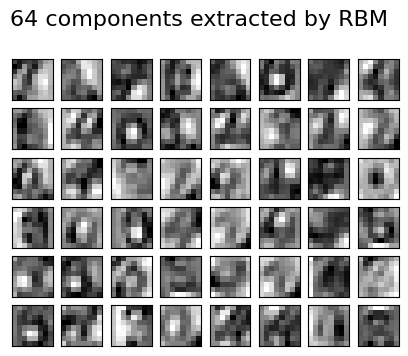

In [95]:
# Plot
plt.figure(figsize=(5, 5))
for i, comp in enumerate(rbm.components_):
    plt.subplot(8, 8, i + 1)
    plt.imshow(comp.reshape((8, 8)), cmap=plt.cm.gray_r, interpolation="nearest")
    plt.xticks(())
    plt.yticks(())
plt.suptitle("64 components extracted by RBM", fontsize=16)